# Fade margins as a function of information: the central tables

Collects the static benchmark (notebooks 02-07) and the history-rung benchmark (13-15) into one table of information rung times model
family, with the hold-out RMSE and the calibrated 99 % margin in each cell; then the unseen-link transfer per family, the margins that follow
the state of the link (quantile models), and the sparse-uplink test.

The static rung is read from the residual files of notebooks 02-07 on all hold-out rows; the history rungs from the files of 13-15 on the
rows with a complete history (99.9 % of the hold-out). Every margin is the empirical quantile of the calibration residuals (`margin_tools.shift_pooled`, the split-conformal shift used in notebooks 17 to 22), as in `09_FADE MARGIN ANALYSIS`.

In [1]:
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb
import xgboost as xgb
from history_features import build, RUNGS
from margin_tools import shift_pooled

RANDOM_STATE = 42
TARGETS = (0.90, 0.95, 0.99)
FAMILIES = ["Linear", "RF", "XGB", "LGBM", "KNN", "ANN", "GRU"]
LABEL = {"Linear": "Linear", "RF": "RF", "XGB": "XGBoost", "LGBM": "LightGBM", "KNN": "k-NN", "ANN": "ANN", "GRU": "GRU"}
COLOUR = {"Linear": "#1f77b4", "RF": "#2ca02c", "XGB": "#d62728", "LGBM": "#ff7f0e", "KNN": "#9467bd", "ANN": "#17becf", "GRU": "#e377c2"}
STATIC_FILE = {"Linear": "MLR", "RF": "RF", "XGB": "XGB", "LGBM": "LGBM", "KNN": "KNN", "ANN": "ANN"}      # notebooks 02-07
RUNG_ORDER = ["static", "H1", "H2", "H3", "H4", "H5", "H6", "H7"]
RUNG_LABEL = {"static": "geometry + sensors", "H1": "link history", "H2": "+ same-channel history", "H3": "+ clock", "H4": "+ SF", "H5": "+ earlier SNR", "H6": "+ sensors", "H7": "+ link level, geometry"}

def rmse(e):
    return float(np.sqrt(np.mean(np.square(e))))

def margins(e_cal, e_test):
    """The margin at each target: the empirical quantile of the calibration residuals (the split-conformal shift of margin_tools), and the share of hold-out residuals it covers."""
    out = {}
    for rho in TARGETS:
        fm = shift_pooled(e_cal, rho)
        out[f"margin {rho:.2f}"], out[f"reached {rho:.2f}"] = fm, float((e_test <= fm).mean())
    return out


In [2]:
# Static rung from the residual files of notebooks 02-07, history rungs from 13-15
rows = {}
for fam, f in STATIC_FILE.items():
    oof = pd.read_csv(f"Residuals/residuals_{f}_oof.csv", usecols=["resid_db"])["resid_db"].to_numpy()
    te = pd.read_csv(f"Residuals/residuals_{f}_test.csv", usecols=["resid_db"])["resid_db"].to_numpy()
    rows[(fam, "static")] = {"hold-out RMSE": rmse(te), "hold-out MAE": float(np.abs(te).mean()), "OOF RMSE": rmse(oof), **margins(oof, te)}
static = pd.DataFrame(rows).T
hist = pd.concat([pd.read_csv(f, index_col=[0, 1]) for f in ("CV_Results/history_benchmark.csv", "CV_Results/history_benchmark_KNN.csv", "CV_Results/history_benchmark_GRU.csv")])
references = hist.loc[hist.index.get_level_values(1) == "-"]
hist = hist.loc[hist.index.get_level_values(1) != "-"]
table = pd.concat([static, hist])
table.index.names = ["family", "rung"]
table.to_csv("CV_Results/information_by_family.csv")

def grid(col, digits):
    g = table[col].unstack("rung").reindex(index=FAMILIES, columns=RUNG_ORDER)
    g.columns = [RUNG_LABEL[c] for c in g.columns]
    return g.round(digits)

print("references (no fitted model): hold-out RMSE and 99 % margin")
print(references[["hold-out RMSE", "margin 0.99", "reached 0.99"]].round(3).to_string())
print("\nhold-out RMSE (dB)")
print(grid("hold-out RMSE", 3).to_string())
print("\nfade margin for 99 % reliability (dB), calibrated on the validation folds")
print(grid("margin 0.99", 2).to_string())
print("\nreliability reached on the hold-out with that margin")
print(grid("reached 0.99", 4).to_string())


references (no fitted model): hold-out RMSE and 99 % margin
                         hold-out RMSE  margin 0.99  reached 0.99
family             rung                                          
link mean          -             5.035       18.308         0.998
previous-hour mean -             2.712       10.600         0.998
previous packet    -             3.044       12.000         0.999

hold-out RMSE (dB)
        geometry + sensors  link history  + same-channel history  + clock   + SF  + earlier SNR  + sensors  + link level, geometry
family                                                                                                                            
Linear               5.252         2.508                   2.399    2.399  2.393          2.372      2.372                   2.372
RF                   4.867         2.345                   2.180    2.180  1.966          1.843      1.844                   1.843
XGB                  4.860         2.337                   2.092  

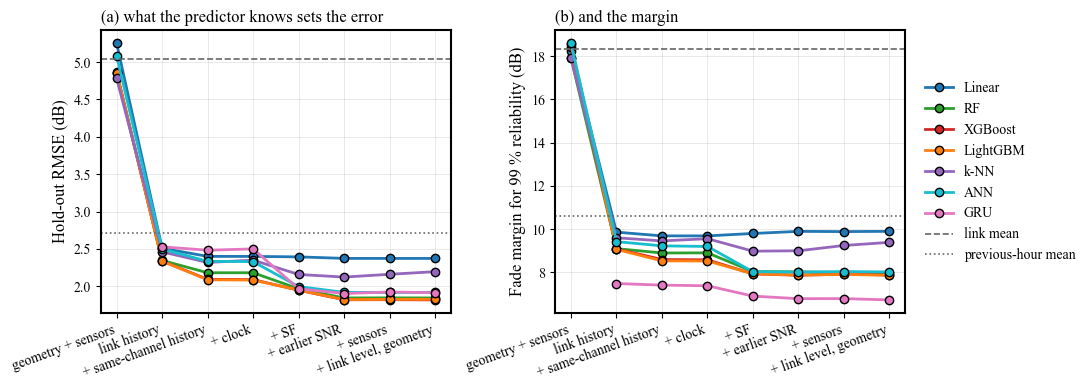

In [3]:
# Figure: the two quantities against the information rung, one line per family
fig, (axA, axB) = plt.subplots(1, 2, figsize=(11, 4))
x = np.arange(len(RUNG_ORDER))
for fam in FAMILIES:
    for ax, col in ((axA, "hold-out RMSE"), (axB, "margin 0.99")):
        v = [table[col].get((fam, r), np.nan) for r in RUNG_ORDER]
        ax.plot(x, v, marker="o", linewidth=2, markersize=6, color=COLOUR[fam], markeredgecolor="black", label=LABEL[fam])
for ax, col, ylabel in ((axA, "hold-out RMSE", "Hold-out RMSE (dB)"), (axB, "margin 0.99", "Fade margin for 99 % reliability (dB)")):
    for name, ls in (("link mean", "--"), ("previous-hour mean", ":")):
        ax.axhline(references.loc[(name, "-"), col], linestyle=ls, color="0.4", linewidth=1.2, label=name)
    ax.set_xticks(x)
    ax.set_xticklabels([RUNG_LABEL[r] for r in RUNG_ORDER], rotation=20, ha="right")
    ax.set_ylabel(ylabel, fontsize=12)
    ax.grid(True, linewidth=0.5, alpha=0.4)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
axA.set_title("(a) what the predictor knows sets the error", loc="left", fontsize=12)
axB.set_title("(b) and the margin", loc="left", fontsize=12)
axB.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=10)
fig.tight_layout()
plt.savefig("Figures/information_by_family.png", dpi=300, bbox_inches="tight")
plt.show()


In [4]:
# A link the model has never seen (rung H4), every family: fitted on five links and tested on the sixth, against the same model fitted on the same
# blocks with the link included; the difference is the transfer penalty
unseen = pd.concat([pd.read_csv(f, index_col=[0, 1]) for f in ("CV_Results/history_unseen_link.csv", "CV_Results/history_unseen_link_KNN.csv", "CV_Results/history_unseen_link_GRU.csv")])
unseen.index.names = ["family", "link"]
unseen["transfer penalty"] = unseen["RMSE on the unseen link"] - unseen["RMSE with the link in training"]
unseen.to_csv("CV_Results/unseen_link_by_family.csv")
summary = unseen.groupby("family").agg(**{"RMSE with the link in training, mean over links": ("RMSE with the link in training", "mean"),
                                           "RMSE on the unseen link, mean over links": ("RMSE on the unseen link", "mean"),
                                           "worst link": ("RMSE on the unseen link", "max"), "transfer penalty, mean": ("transfer penalty", "mean"),
                                           "transfer penalty, largest": ("transfer penalty", "max"), "reached 0.99, mean over links": ("reached on the unseen link", "mean")}).reindex(FAMILIES)
summary["hold-out RMSE at H4, whole training window"] = [table["hold-out RMSE"].get((f, "H4"), np.nan) for f in FAMILIES]
print(summary.round(3).to_string())
print("\nper link, RMSE on the unseen link (dB)")
print(unseen["RMSE on the unseen link"].unstack("link").reindex(FAMILIES).round(2).to_string())
print("\nper link, transfer penalty (dB)")
print(unseen["transfer penalty"].unstack("link").reindex(FAMILIES).round(2).to_string())

        RMSE with the link in training, mean over links  RMSE on the unseen link, mean over links  worst link  transfer penalty, mean  transfer penalty, largest  reached 0.99, mean over links  hold-out RMSE at H4, whole training window
family                                                                                                                                                                                                                                     
Linear                                            2.395                                     2.400       2.603                   0.004                      0.015                          0.997                                       2.393
RF                                                2.047                                     2.056       2.233                   0.009                      0.042                          0.997                                       1.966
XGB                                               2.017 

In [5]:
# Margins that follow the state of the link: quantile models on rung H4 (and H6 at 99 %)
train = pd.read_csv("Data_Files/history_train.csv")
test = pd.read_csv("Data_Files/history_test.csv")
d = pd.concat([train, test], ignore_index=True)
d["t"] = pd.to_datetime(d["t"], utc=True)
d = d.sort_values("t").reset_index(drop=True)
fold = d["fold"].to_numpy()
H = {k.split()[0]: v for k, v in RUNGS.items()}
ok = (d["y"].notna() & d[H["H7"]].notna().all(axis=1)).to_numpy()
cal, ev = ok & (fold >= 0) & (fold < 9), ok & (fold == 9)
y, work = d["y"].to_numpy(), d["work"].to_numpy() == 1
X_all = d[H["H7"]].copy()
X_all = X_all.fillna(X_all[ok & (fold < 9)].median())
best = json.load(open("CV_Results/history_best_params.json"))

def oof_and_test(make, cols):
    X = X_all[cols].to_numpy()
    q = np.full(len(d), np.nan)
    for k in range(5):
        tr, va = ok & (fold < k), ok & (fold == k)
        q[va] = make().fit(X[tr], y[tr]).predict(X[va])
    tr = ok & (fold < 9)
    q[ev] = make().fit(X[tr], y[tr]).predict(X[ev])
    return q

def state_margin(q, rho):
    """The quantile prediction shifted by a constant chosen on the validation folds, so that the margin is calibrated like the fixed one."""
    m = q + shift_pooled((y - q)[cal], rho)
    return {"mean margin": float(m[ev].mean()), "in working hours": float(m[ev & work].mean()), "other hours": float(m[ev & ~work].mean()), "reached": float((y[ev] <= m[ev]).mean())}

qrows = {}
for rho in TARGETS:
    fm = shift_pooled(y[cal], rho)
    qrows[(f"{rho:.2f}", "one fixed margin above the previous-hour mean", "H1")] = {"mean margin": fm, "in working hours": fm, "other hours": fm, "reached": float((y[ev] <= fm).mean())}
quantile_models = {
    "LightGBM": lambda rho: lgb.LGBMRegressor(objective="quantile", alpha=rho, subsample_freq=1, random_state=RANDOM_STATE, n_jobs=8, verbose=-1, **best["LGBM"]),
    "XGBoost": lambda rho: xgb.XGBRegressor(objective="reg:quantileerror", quantile_alpha=rho, device="cuda", tree_method="hist", random_state=RANDOM_STATE, **best["XGB"]),
}
for name, make in quantile_models.items():
    for rung, rhos in (("H4", TARGETS), ("H6", (0.99,))):
        for rho in rhos:
            t0 = time.time()
            qrows[(f"{rho:.2f}", f"{name} quantile model", rung)] = state_margin(oof_and_test(lambda: make(rho), H[rung]), rho)
            print(f"{name} {rung} rho={rho}: {qrows[(f'{rho:.2f}', f'{name} quantile model', rung)]['mean margin']:.2f} dB mean margin ({time.time() - t0:.0f} s)")


LightGBM H4 rho=0.9: 2.24 dB mean margin (188 s)


LightGBM H4 rho=0.95: 2.95 dB mean margin (180 s)


LightGBM H4 rho=0.99: 4.68 dB mean margin (178 s)


LightGBM H6 rho=0.99: 4.18 dB mean margin (228 s)


/home/nahshon/envs/ml001/lib/python3.12/site-packages/xgboost/core.py:158: UserWarning: [21:08:40] WARNING: /workspace/src/common/error_msg.cc:58: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  warnings.warn(smsg, UserWarning)


XGBoost H4 rho=0.9: 2.22 dB mean margin (50 s)


XGBoost H4 rho=0.95: 2.93 dB mean margin (48 s)


XGBoost H4 rho=0.99: 4.71 dB mean margin (47 s)


XGBoost H6 rho=0.99: 4.21 dB mean margin (58 s)


In [6]:
# ANN with the pinball loss at 99 %, rungs H4 and H6 (same network and protocol as notebook 13)
import tensorflow as tf
from tensorflow import keras
tf.config.set_visible_devices([], "GPU")

class ANNQuantile:
    def __init__(self, layers, rho, seeds=(0, 1, 2)):
        self.layers, self.rho, self.seeds, self.scaler, self.nets = layers, rho, seeds, StandardScaler(), []
    def fit(self, X, y):
        Xs = self.scaler.fit_transform(X).astype(np.float32); y = y.astype(np.float32)
        n_val = max(1, len(Xs) // 10)
        rho = self.rho
        pinball = lambda t, q: tf.reduce_mean(tf.maximum(rho * (t - q), (rho - 1) * (t - q)))
        self.nets = []
        for seed in self.seeds:
            tf.keras.utils.set_random_seed(seed)
            net = keras.Sequential([keras.Input(shape=(Xs.shape[1],))] + [keras.layers.Dense(n, activation="relu") for n in self.layers] + [keras.layers.Dense(1)])
            net.compile(optimizer=keras.optimizers.Adam(1e-3), loss=pinball)
            net.fit(Xs[:-n_val], y[:-n_val], validation_data=(Xs[-n_val:], y[-n_val:]), epochs=200, batch_size=2048, verbose=0,
                    callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True), keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=4, min_lr=1e-5)])
            self.nets.append(net)
        return self
    def predict(self, X):
        Xs = self.scaler.transform(X).astype(np.float32)
        return np.mean([net.predict(Xs, batch_size=8192, verbose=0).ravel() for net in self.nets], axis=0)

layers = tuple(best["ANN"])
for rung in ("H4", "H6"):
    t0 = time.time()
    qrows[("0.99", "ANN quantile model", rung)] = state_margin(oof_and_test(lambda: ANNQuantile(layers, 0.99), H[rung]), 0.99)
    print(f"ANN {rung} rho=0.99: {qrows[('0.99', 'ANN quantile model', rung)]['mean margin']:.2f} dB mean margin ({time.time() - t0:.0f} s)")

state = pd.DataFrame(qrows).T
state.index.names = ["target", "model", "rung"]
state.to_csv("CV_Results/state_margins.csv")
print(state.round(3).to_string())


I0000 00:00:1792177918.365432 3855883 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792177918.523203 3855883 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792177919.410267 3855883 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


W0000 00:00:1792177920.395632 3855883 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


I0000 00:00:1792177920.946827 3864208 service.cc:153] XLA service 0x79bd90019950 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792177920.946841 3864208 service.cc:161]   StreamExecutor [0]: Host, Default Version (Driver: 0.0.0; Runtime: 0.0.0; Toolkit: 0.0.0; DNN: 0.0.0)
I0000 00:00:1792177920.957154 3864208 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792177921.114127 3864208 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


ANN H4 rho=0.99: 4.90 dB mean margin (464 s)


ANN H6 rho=0.99: 4.65 dB mean margin (494 s)
                                                           mean margin  in working hours  other hours  reached
target model                                         rung                                                     
0.90   one fixed margin above the previous-hour mean H1          3.815             3.815        3.815    0.917
0.95   one fixed margin above the previous-hour mean H1          5.309             5.309        5.309    0.967
0.99   one fixed margin above the previous-hour mean H1         10.600            10.600       10.600    0.998
0.90   LightGBM quantile model                       H4          2.236             2.546        2.106    0.901
0.95   LightGBM quantile model                       H4          2.951             3.423        2.752    0.953
0.99   LightGBM quantile model                       H4          4.681             5.613        4.288    0.993
                                                     H6          4.

In [7]:
# Sparser uplinks: every 10th and every 60th packet of each link kept, anchor = mean of the previous 20 kept packets, LightGBM on rung H4.
# The references are compared on the rows where all of them exist.
srows = {}
raw = pd.concat([pd.read_csv("Data_Files/train.csv").assign(fold=np.load("Data_Files/train_folds.npy")), pd.read_csv("Data_Files/test.csv").assign(fold=9)], ignore_index=True)
raw["t"] = pd.to_datetime(raw["time"], utc=True, format="mixed")
raw = raw.drop(columns="time").sort_values(["device_id", "t"])
for k in (10, 60):
    s = build(raw[raw.groupby("device_id").cumcount() % k == 0], anchor="m20")
    s_fold, s_ok = s["fold"].to_numpy(), s["y"].notna().to_numpy()      # windows shorter than the uplink interval are undefined; LightGBM takes them as missing
    s_cal, s_ev = s_ok & (s_fold >= 0) & (s_fold < 9), s_ok & (s_fold == 9)
    Xs, ys = s[H["H4"]].to_numpy(), s["y"].to_numpy()
    q = np.full(len(s), np.nan)
    for f in range(5):
        tr, va = s_ok & (s_fold < f), s_ok & (s_fold == f)
        q[va] = lgb.LGBMRegressor(subsample_freq=1, random_state=RANDOM_STATE, n_jobs=8, verbose=-1, **best["LGBM"]).fit(Xs[tr], ys[tr]).predict(Xs[va])
    tr = s_ok & (s_fold < 9)
    q[s_ev] = lgb.LGBMRegressor(subsample_freq=1, random_state=RANDOM_STATE, n_jobs=8, verbose=-1, **best["LGBM"]).fit(Xs[tr], ys[tr]).predict(Xs[s_ev])
    errors = {"previous kept packet": ys - s["r_lag1"].to_numpy(), "mean of the previous 20 kept packets": ys, "mean of the previous 24 hours": ys - s["r_m24h"].to_numpy(), "LightGBM on rung H4": ys - q}
    have = np.all([~np.isnan(e) for e in errors.values()], axis=0)
    for name, e in errors.items():
        fm = shift_pooled(e[s_cal & have], 0.99)
        srows[(f"every {k} min", name)] = {"hold-out RMSE": rmse(e[s_ev & have]), "margin 0.99": fm, "reached": float((e[s_ev & have] <= fm).mean()), "hold-out rows": int((s_ev & have).sum())}
sparse = pd.DataFrame(srows).T
sparse.index.names = ["uplink interval", "predictor"]
sparse.to_csv("CV_Results/sparse_uplinks.csv")
print(sparse.round(3).to_string())


                                                      hold-out RMSE  margin 0.99  reached  hold-out rows
uplink interval predictor                                                                               
every 10 min    previous kept packet                          3.509       12.000    0.999        53199.0
                mean of the previous 20 kept packets          2.701       11.900    0.998        53199.0
                mean of the previous 24 hours                 3.233       13.085    0.997        53199.0
                LightGBM on rung H4                           2.261       10.406    0.998        53199.0
every 60 min    previous kept packet                          3.162       12.000    0.999         8862.0
                mean of the previous 20 kept packets          3.224       13.100    0.997         8862.0
                mean of the previous 24 hours                 3.230       13.143    0.998         8862.0
                LightGBM on rung H4                    